# 预报时效拆分

包名 `time_split_linear`。插件 `TimeSplit` 只处理时间维插值；多时效读拼在共用 `utils.grid_combine`。空间网格不改。

在本包目录下使用。命令行没写的参数先读 `resource/conf.ini`，配置里也没有再用代码预设。`TimeSplit` 的 CLI 经模块级 `process` 读数并调用插件；插件 `TimeSplit.process` 只接收内存场。

时效三元组是 `[起点, 终点, 步长]`，终点包含在结果中。覆盖 0 到 72 小时时，3 小时输入写 `0,72,3`，1 小时输出写 `0,72,1`。`TimeSplit` 打开分钟输出时，输入仍写小时，输出改写分钟，例如 `0,6,1` 对 `0,360,10`。


## TimeSplit

插件只处理内存场。路径读数用 CLI 模块级 `process`（内部完成解析、读数拼接并调用插件）。通用读拼只调 `utils.grid_combine.read_multi_griddata`：`index=dtime` 时 `is_ob=False`；`index=time` 时 `is_ob=True`（多钟点沿 time 拼，`dtime=0`）。默认沿 `dtime` 插值；没有时效 0 时补一帧全 0，已有则保留原值。`index="time"` 沿起报时间插值；输出三元组是相对最早起报时间的偏移。默认 `slinear`，目标超出源坐标两端时外推。

适用于逐 3 小时一帧收成逐小时一帧。`is_Min=True` 时输出按分钟：0 到 6 小时收成逐 10 分钟，读数用 `input_fh=[0,6,1]`，输出写 `output_fh_list=[0, 360, 10]`。累计序列插值后仍是累计；再设 `delta=1`（与 `is_Min` 同单位：小时或分钟）得到增量。

读数时给出 `uv_fmt`，把读到的 V 场作为 `process` 的 `uv`，插值前只保留风速。给出 `output_fmt` 时，沿 `dtime` 每个输出时效写一个 nc，沿 `time` 每个输出起报时间写一个 nc，小于 0 的值改为 0。分钟起报时间的输出模板要带 `FF`。

### 构造参数

| 参数 | 含义 | 默认 |
|---|---|---|
| `output_fh_list` | 输出坐标 `[起点, 终点, 步长]`，终点包含在结果中。`is_Min` 为假时单位是小时，为真时是分钟 | 必填 |
| `interp_method` | 传给 `DataArray.interp` 的方法 | `slinear` |
| `output_fmt` | 输出路径模板；空则不写文件 | `None` |
| `delta` | 累计场差分间隔；单位与 `is_Min` 一致（假=小时，真=分钟）；有值则差分后裁负；空则不做差分 | `None` |
| `is_Min` | 为真时输出坐标按分钟。沿 `dtime` 时源时效先乘 60；沿 `time` 时只改起报时间偏移的单位 | `False` |
| `index` | 插值轴：`dtime` 预报时效，`time` 起报时间 | `dtime` |

### 读数参数（CLI `process`）

| 参数 | 含义 |
|---|---|
| `input_fh` / `fhs` | 输入时效三元组或已展开序列，单位小时 |
| `input_fmt` | 输入路径模板 |
| `time` | `index=dtime` 时一个起报时间；`index=time` 时起报时间列表 |
| `uv_fmt` | 可选 V 分量路径模板 |
| `is_fill0` | 读数时时效 0 不读文件、改用全 0 |

### `process` 参数

| 参数 | 类型 | 含义 |
|---|---|---|
| `fcst` | `xr.DataArray` | 已读入内存的格点场，维度含 `member, level, time, dtime, lat, lon`。沿 `dtime` 时时效单位为小时 |
| `uv` | `xr.DataArray` 或 `None` | 可选 V 分量场，类型与 `fcst` 相同；给出时 `fcst` 作为 U，插值前只保留风速 |

返回 `(细时间场, 插值前的粗时间场)`，类型为 `(xr.DataArray | None, xr.DataArray | None)`。插值失败时返回 `(None, None)`。`is_Min` 为真且沿 `dtime` 时，细时效场的 `dtime` 是分钟，粗时效场仍是小时。

### 插件示例

```python
from cli.cal_griddata_TimeSplit_plugin_cli import process

# 逐 3 小时插成逐小时（读数+插值都在 process 内）
fine, raw = process(
    input_fh="0,72,3",
    output_fh="0,72,1",
    input_fmt="fcst/YYYYMMDDHH.TTT.nc",
    time="2023070100",
)

# 累计序列：插成逐小时后再差分
hourly_increment, _ = process(
    input_fh="0,72,3",
    output_fh="0,72,1",
    input_fmt="rain/YYYYMMDDHH.TTT.nc",
    time="2023070100",
    delta="1",
)

# 逐小时收成逐 10 分钟
minute_field, hourly_field = process(
    input_fh="0,6,1",
    output_fh="0,360,10",
    is_min=True,
    input_fmt="fcst/YYYYMMDDHH.TTT.nc",
    time="2023070100",
)

# 多钟点分析沿 time 插到逐 30 分钟
fine_issue, raw_issue = process(
    index="time",
    input_fh="0,0,1",
    output_fh="0,120,30",
    is_min=True,
    input_fmt="analysis/YYYYMMDDHH.TTT.nc",
    time="2023070100,2023070101,2023070102",
)
```

### 命令行

命令行与 `process(...)` / `CalGriddataTimeSplitPluginCli.call(...)` 都会走模块级 `process`：先按优先级补齐参数，再读数并调用插件。

```bash
python -m cli.cal_griddata_TimeSplit_plugin_cli --input-fh 0,72,3 --output-fh 0,72,1 --input-fmt fcst/YYYYMMDDHH.TTT.nc --time 2023070100
python cli/cal_griddata_TimeSplit_plugin_cli.py --input-fh 0,72,3 --output-fh 0,72,1 --interp-method linear --delta 1 --input-fmt rain/YYYYMMDDHH.TTT.nc --time 2023070100
python -m cli.cal_griddata_TimeSplit_plugin_cli --input-fh 0,6,1 --output-fh 0,360,10 --is-min --input-fmt fcst/YYYYMMDDHH.TTT.nc --time 2023070100
python -m cli.cal_griddata_TimeSplit_plugin_cli --index time --input-fh 0,0,1 --output-fh 0,120,30 --is-min --input-fmt analysis/YYYYMMDDHH.TTT.nc --time 2023070100,2023070101,2023070102
```


### 调用示例（EC APCP）

用本包样例 `resource/EC/APCP` 起报 `2026072700` 的累计降水（时效 `0/3/6`）：`TimeSplit` 插到逐小时并 `delta=1` 得时段降水。作图为输入（稀疏累计）与输出（加密时段量）对照；图题只写物理量与时效，含义见代码注释。


In [1]:
from __future__ import annotations

import sys
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import meteva_base as meb
from meteva_base.tool.color_tools import get_cmap_and_clevs_by_element_name
import meteva_base.tool.plot_tools as _plot_tools
from meteva_base.tool.plot_tools import pcolormesh_2d_grid

# 样例环境可能无完整底图 shapefile，跳过以免报错
_plot_tools.add_china_map_2basemap = lambda *args, **kwargs: None

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

ROOT = Path.cwd().resolve()
if not (ROOT / "cli").is_dir() and (ROOT.parent / "cli").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.cal_griddata_TimeSplit_plugin import TimeSplit
from utils.grid_combine import read_multi_griddata

ISSUE = datetime(2026, 7, 27, 0)
INPUT_FMT = str(ROOT / "resource" / "EC" / "APCP" / "YYYY" / "YYYYMMDD" / "YYYYMMDDHH.TTT.nc")
# 对应文件：.../2026072700.000.nc、.003.nc、.006.nc
raw = read_multi_griddata(INPUT_FMT, ISSUE, [0, 3, 6], is_fill0=False)
assert raw is not None, f"未读到数据: {INPUT_FMT}"

splitter = TimeSplit(
    output_fh_list=[0, 6, 1],
    interp_method="slinear",
    delta="1",
    is_Min=False,
    index="dtime",
)
fine, coarse = splitter.process(raw)
assert fine is not None and coarse is not None
print("输入 dtime:", list(map(int, coarse.dtime.values)))
print("输出 dtime:", list(map(int, fine.dtime.values)))
print(fine)


d:\workspace\test\.venv\Lib\site-packages\meteva_base\basicdata\const.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


Read FILE:  0 2026-07-27 00:00:00 0 D:\workspace\test\00temp\time_split_linear\resource\EC\APCP\2026\20260727\2026072700.000.nc
<xarray.DataArray 'data0' (member: 1, level: 1, time: 1, dtime: 3, lat: 601,
                           lon: 801)> Size: 6MB
array([[[[[[ 0. ,  0. ,  0. , ...,  0. ,  0. ,  0. ],
           [ 0. ,  0. ,  0. , ...,  0. ,  0. ,  0. ],
           [ 0. ,  0. ,  0. , ...,  0. ,  0. ,  0. ],
           ...,
           [ 0. ,  0. ,  0. , ...,  0. ,  0. ,  0. ],
           [ 0. ,  0. ,  0. , ...,  0. ,  0. ,  0. ],
           [ 0. ,  0. ,  0. , ...,  0. ,  0. ,  0. ]],

          [[ 2.7,  2.3,  1.4, ...,  0. ,  0. ,  0. ],
           [ 2.6,  2.8,  1.6, ...,  0. ,  0. ,  0. ],
           [ 2.4,  1.9,  1.8, ...,  0. ,  0. ,  0. ],
           ...,
           [ 0. ,  0. ,  0. , ...,  0. ,  0. ,  0. ],
           [ 0. ,  0. ,  0. , ...,  0. ,  0. ,  0. ],
           [ 0. ,  0. ,  0. , ...,  0. ,  0. ,  0. ]],

          [[ 8. ,  7.2,  5.6, ...,  0. ,  0. ,  0. ],
         

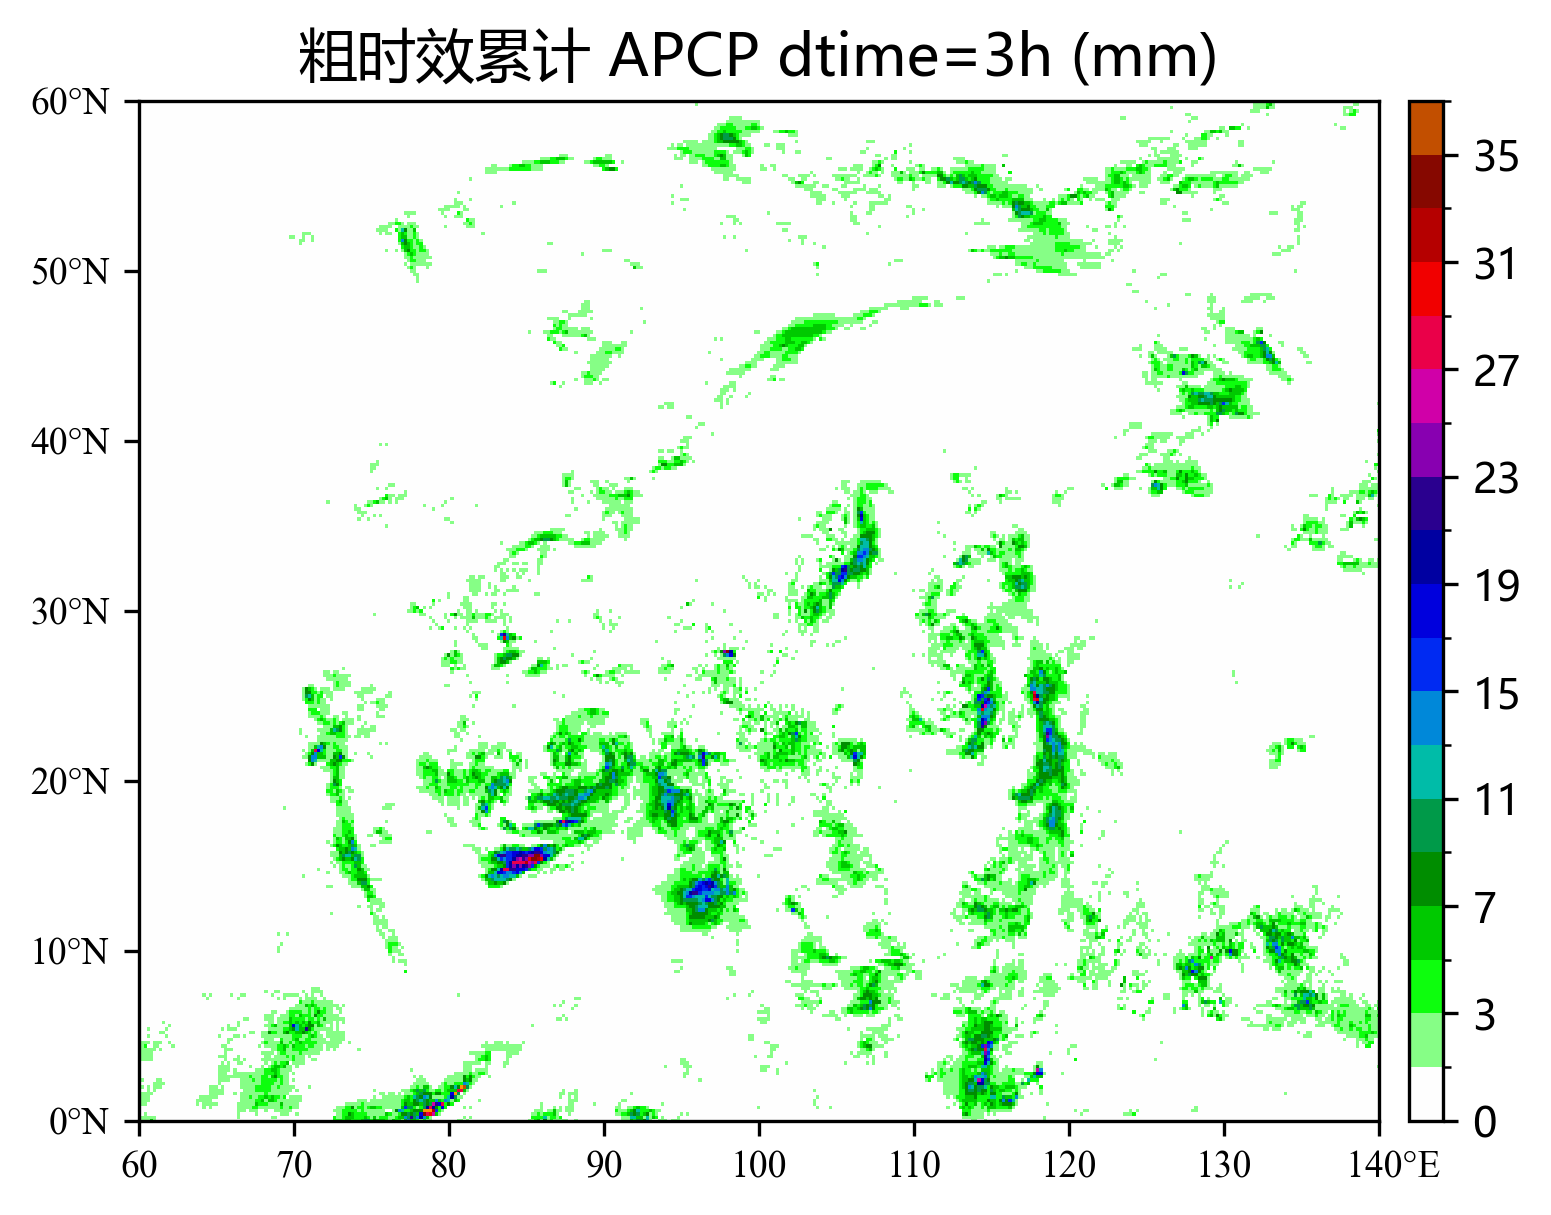

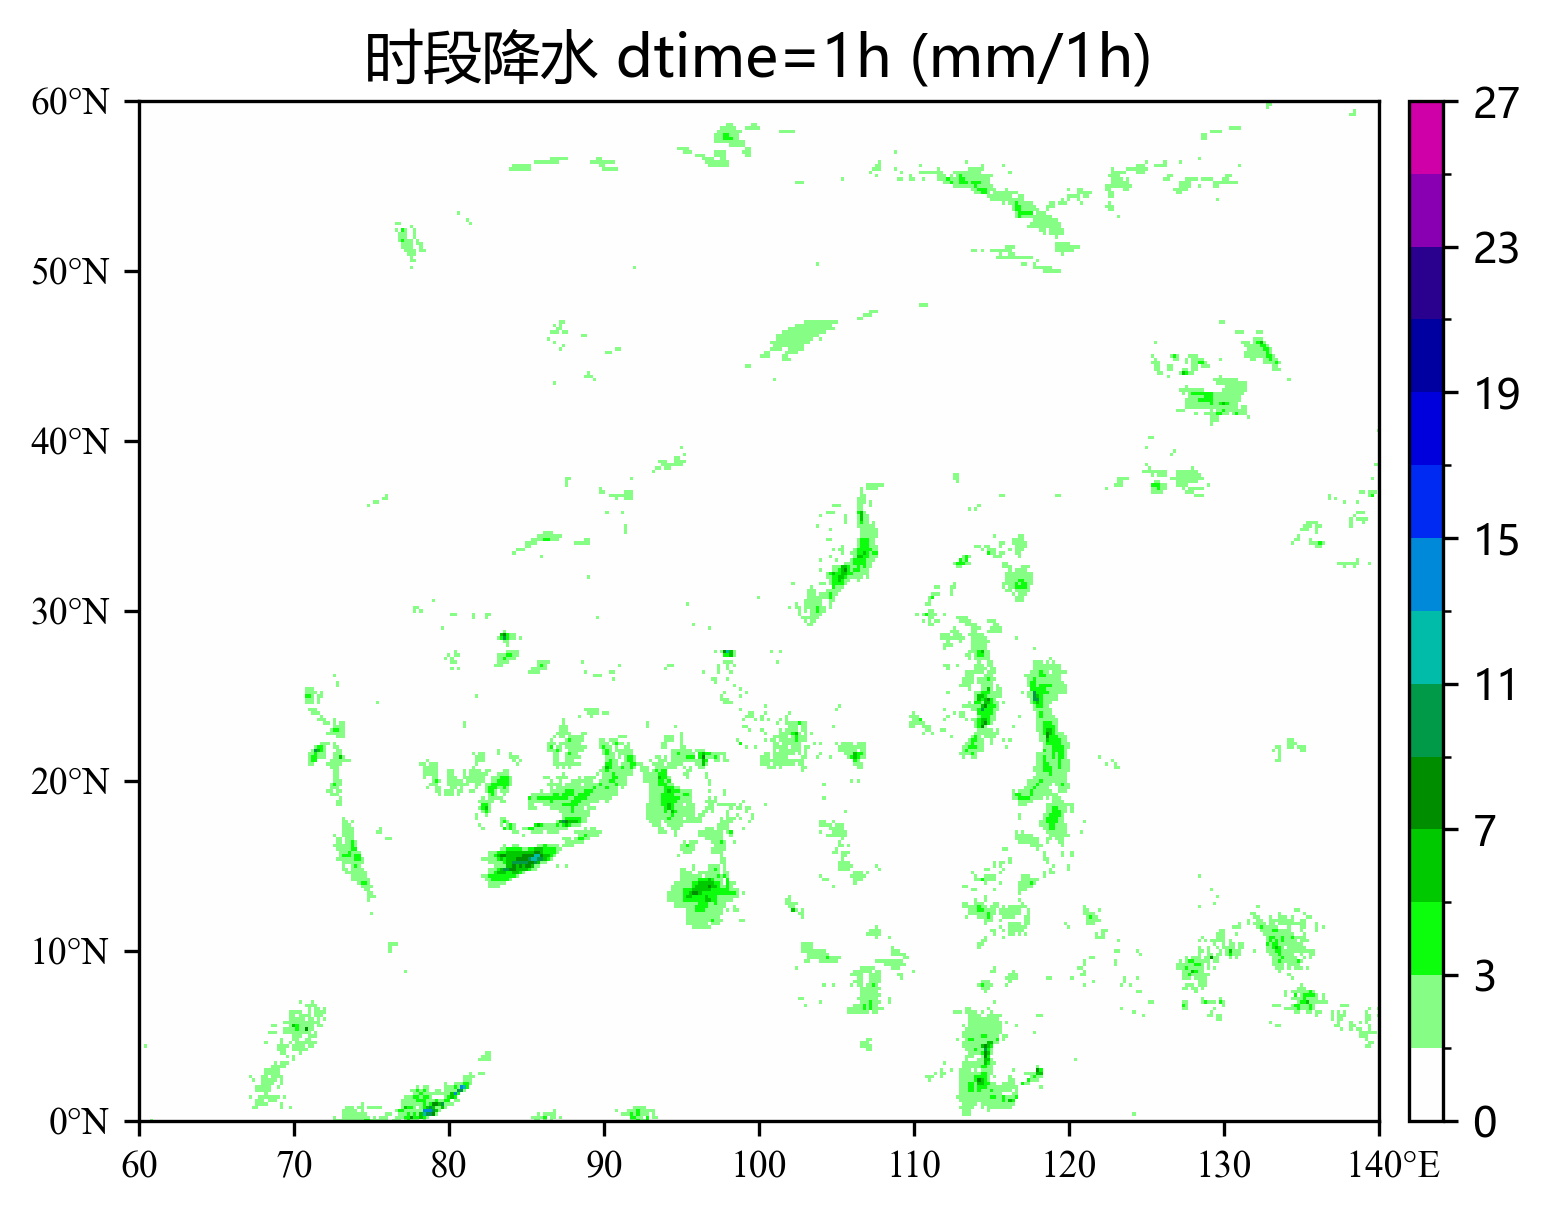

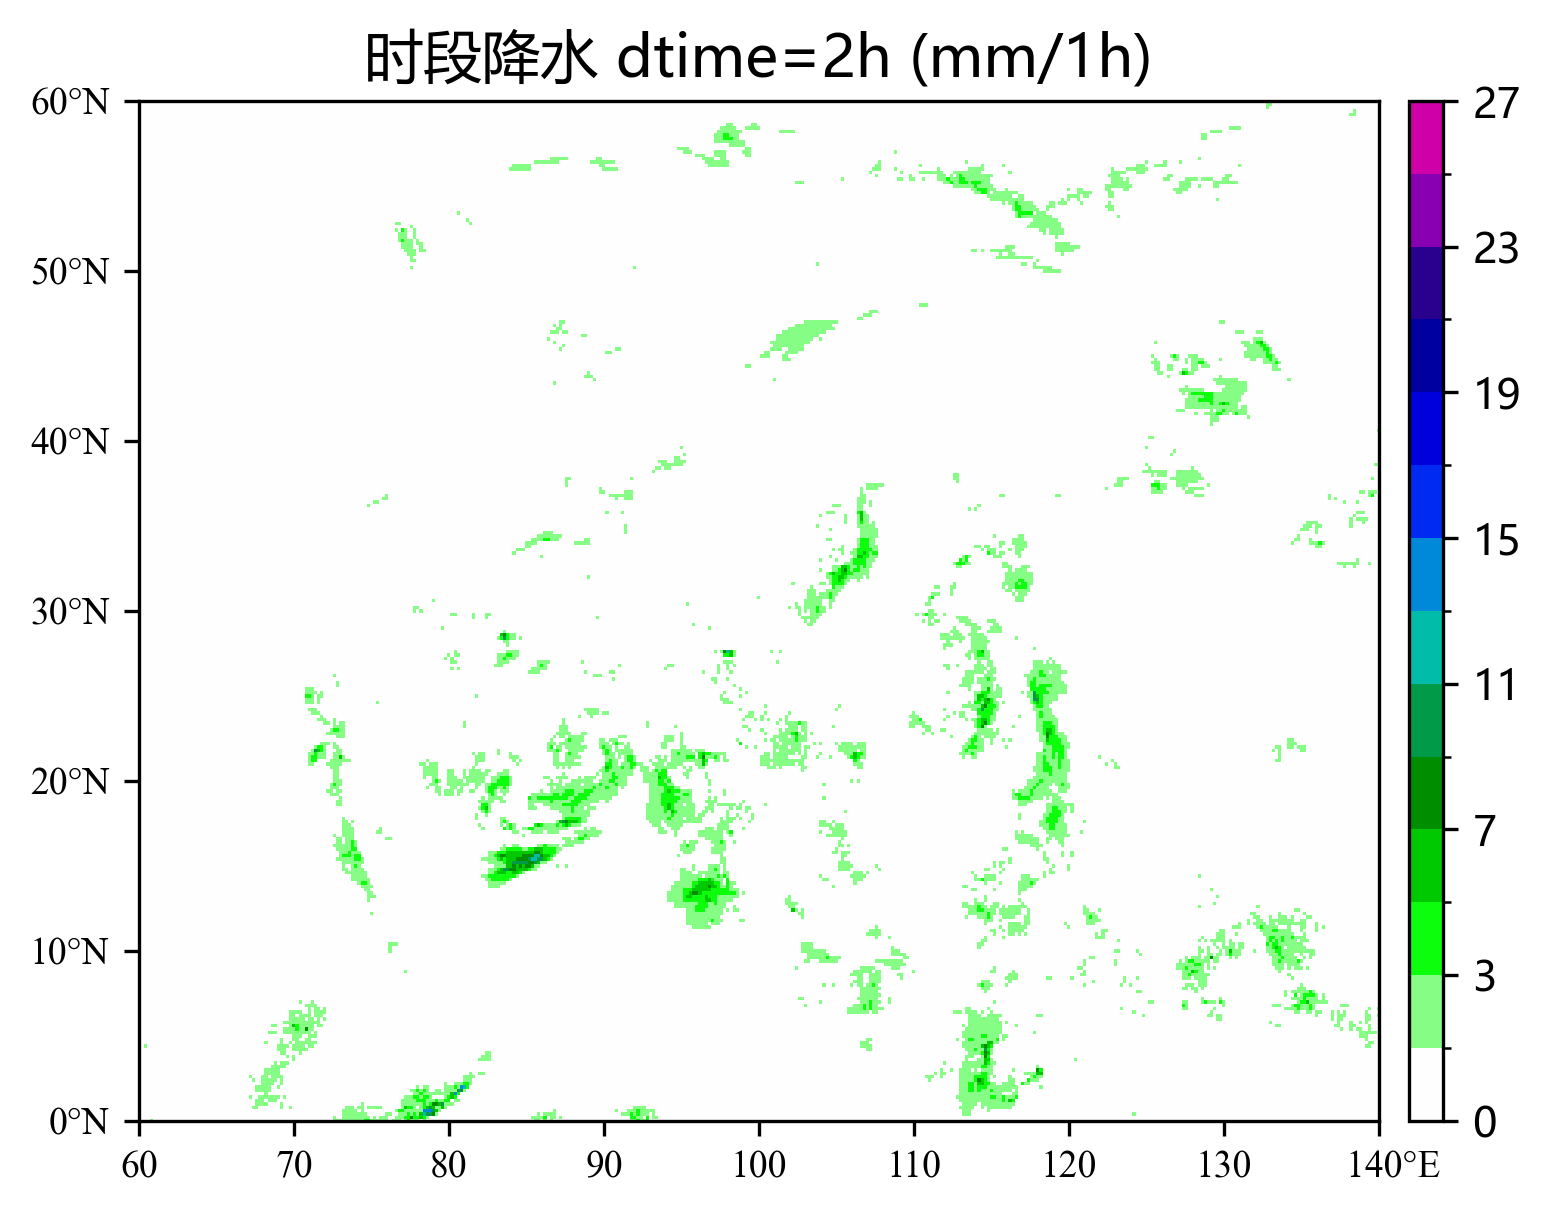

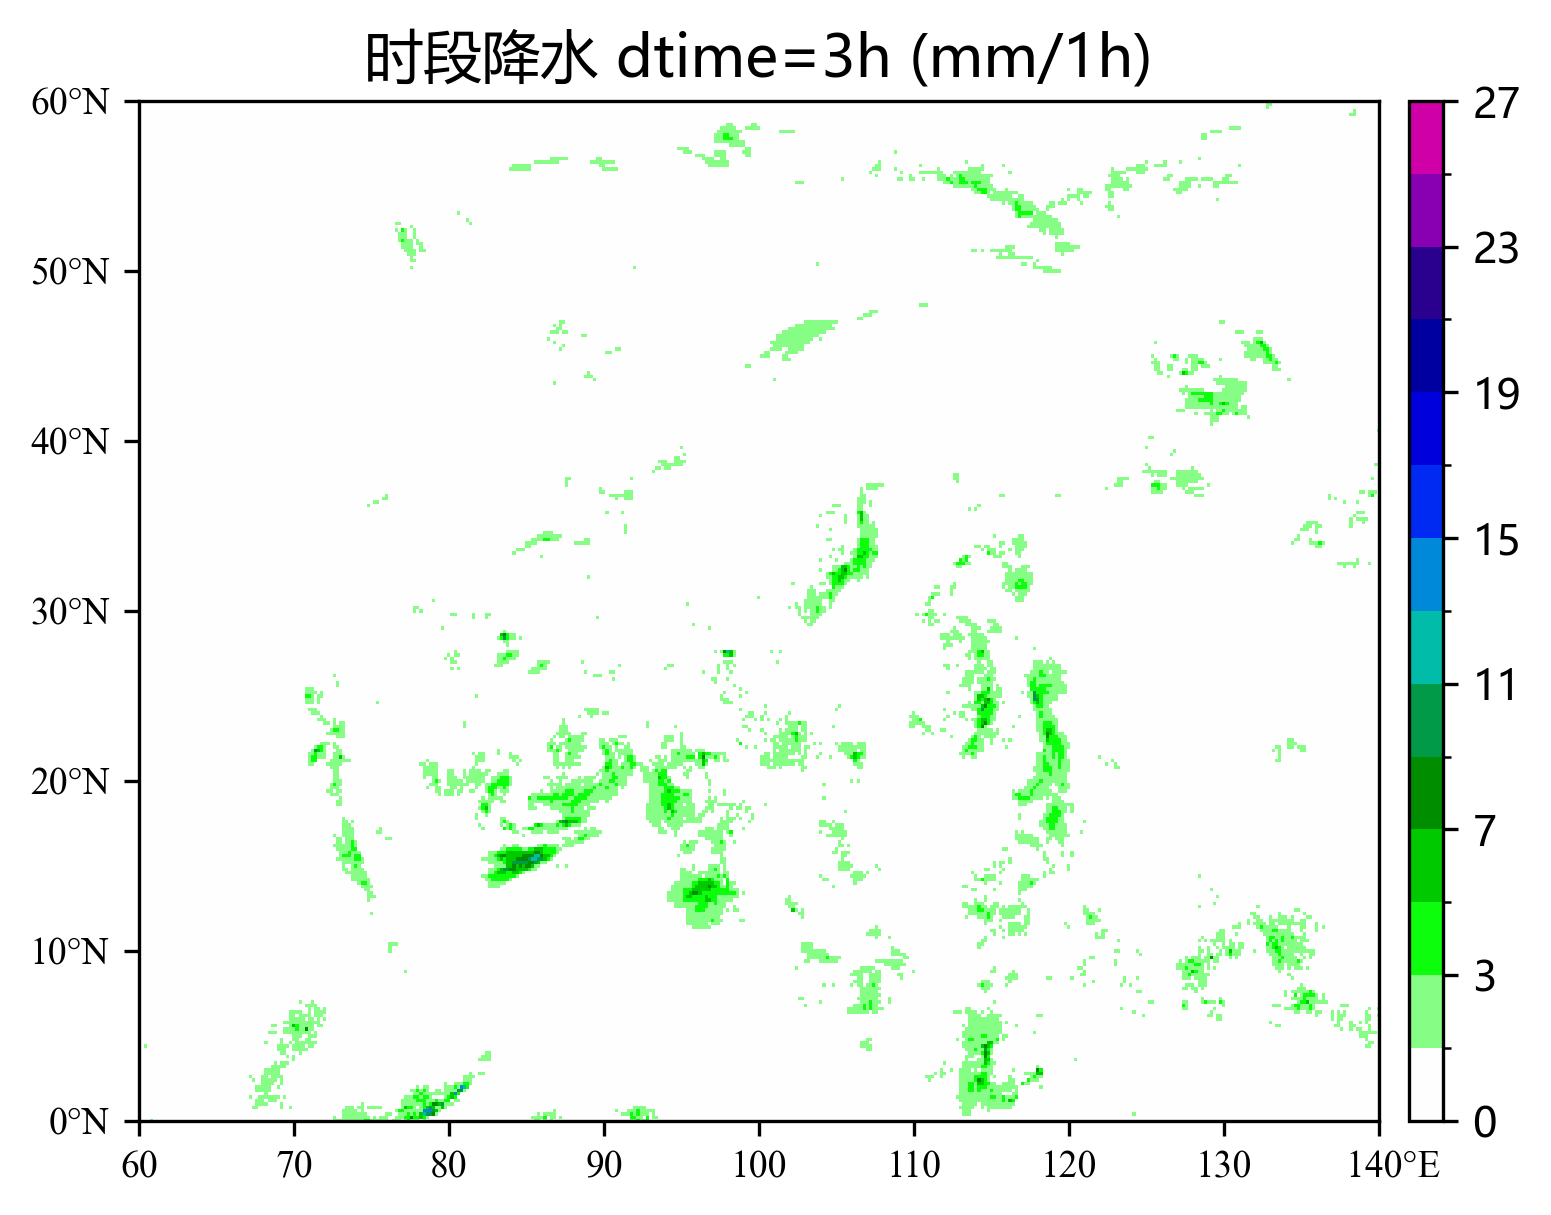

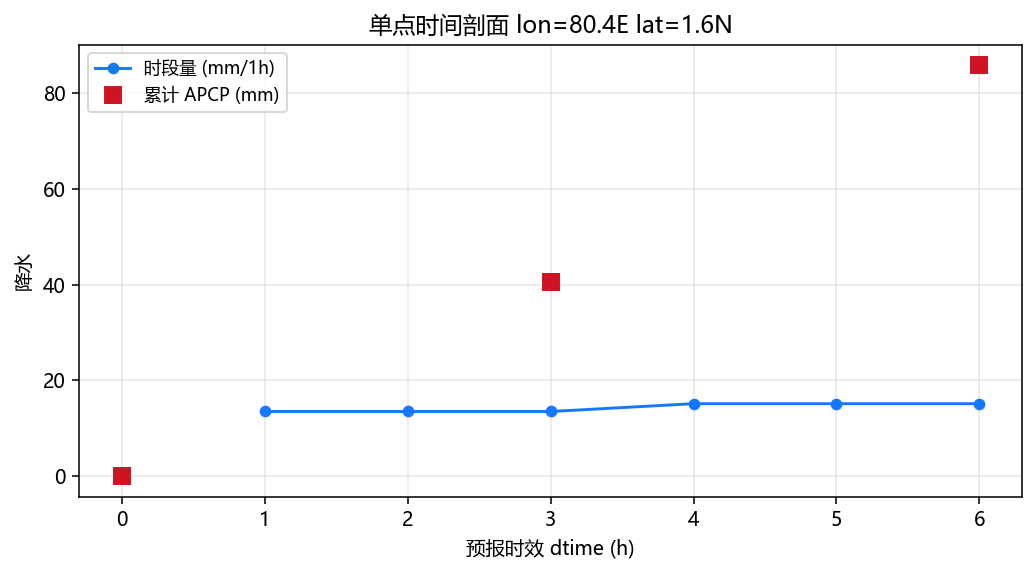

剖面点 lon=80.4, lat=1.6


In [2]:
# 共用 rain_1h 色标（抽稀档，避免对照图被截断）
cmap, clevs = get_cmap_and_clevs_by_element_name("rain_1h")
if len(clevs) >= 20:
    step = max(1, (len(clevs) - 2) // 12)
    keep = [clevs[0], *clevs[1:-1:step], clevs[-1]]
    seen, clevs = set(), []
    for v in keep:
        if v not in seen:
            seen.add(v)
            clevs.append(v)


def thin(da, step=2):
    return da.isel(lat=slice(None, None, step), lon=slice(None, None, step))


lead = 3
inp = coarse.sel(dtime=[lead])  # 输入：粗时效累计

# 1) 输入场
pcolormesh_2d_grid(
    thin(inp),
    title=f"粗时效累计 APCP dtime={lead}h (mm)",
    cmap=cmap,
    clevs=clevs,
    show=True,
)

# 2) 输出场：加密后的逐小时时段降水（dtime=1/2/3）
for h in (1, 2, 3):
    pcolormesh_2d_grid(
        thin(fine.sel(dtime=[h])),
        title=f"时段降水 dtime={h}h (mm/1h)",
        cmap=cmap,
        clevs=clevs,
        show=True,
    )

# 3) 单点时间剖面：输入稀疏累计 vs 输出加密时段
vals = np.asarray(fine.values, dtype=float)
slab = np.nansum(vals[0, 0, 0], axis=0)
j, i = np.unravel_index(np.nanargmax(slab), slab.shape)
lat_p = float(fine.lat.values[j])
lon_p = float(fine.lon.values[i])
coarse_ts = [
    float(coarse.sel(dtime=d, lat=lat_p, lon=lon_p, method="nearest").values.squeeze())
    for d in (0, 3, 6)
]
fine_leads = list(map(int, fine.dtime.values))
fine_ts = [
    float(fine.sel(dtime=d, lat=lat_p, lon=lon_p, method="nearest").values.squeeze())
    for d in fine_leads
]

fig, ax = plt.subplots(figsize=(7.5, 4.2), dpi=140)
ax.plot(fine_leads, fine_ts, "-o", color="#1677ff", ms=5, label="时段量 (mm/1h)")
ax.plot([0, 3, 6], coarse_ts, "s", color="#cf1322", ms=8, label="累计 APCP (mm)")
ax.set_xlabel("预报时效 dtime (h)")
ax.set_ylabel("降水")
ax.set_title(f"单点时间剖面 lon={lon_p:.1f}E lat={lat_p:.1f}N")
ax.grid(True, alpha=0.3)
ax.legend(loc="best", fontsize=9)
fig.tight_layout()
plt.show()
print(f"剖面点 lon={lon_p:.1f}, lat={lat_p:.1f}")


## 多时效读拼（共用工具）

`TimeSplit` CLI 读数走共用 `utils.grid_combine.read_multi_griddata`（同一起报沿 `dtime`；`index=time` 时 `is_ob=True`，按钟点偏移读拼）。通用拼接为 `concat_griddata`。本包不再提供独立的多时次读拼 CLI。


## 命令行公共规则

在本包目录执行。每条命令都可以用 `python -m cli.<模块>_cli`，也可以直接运行 `python cli/<模块>_cli.py`。

参数优先级是：命令行显式传入，然后是 `resource/conf.ini` 里的非空项，再是代码预设。`--config` 可以改读另一个 ini，相对路径按本包目录解析。

`input_fh`、`output_fh`、`input_fmt`、`time` 命令行和配置都空着时会报错。

`TimeSplit` CLI 会进入实际读数/`process`。

```bash
python -m cli.cal_griddata_TimeSplit_plugin_cli --input-fh 0,72,3 --output-fh 0,72,1 --input-fmt fcst/YYYYMMDDHH.TTT.nc --time 2023070100 --uv-fmt windv/YYYYMMDDHH.TTT.nc --output-fmt out/YYYYMMDDHH.TTT.nc
python -m cli.cal_griddata_TimeSplit_plugin_cli --input-fh 0,6,1 --output-fh 0,360,10 --is-min --input-fmt fcst/YYYYMMDDHH.TTT.nc --time 2023070100
```
